# Invoice parser demo: from a supplier invoice to a changed menu decision

The Menu Profit Simulator's costs were typed in as CSVs. A restaurant has **invoices**. This notebook follows one constructed invoice through the parser extension:

1. an LLM **reads** the text and copies raw fields plus a quote of each line (it never converts a unit or does arithmetic);
2. plain **code** converts units, computes costs, checks the line totals and flags anything uncertain;
3. a **person** reviews the staged rows and approves them (here a reviewer's decisions are simulated by code, and said so);
4. the unchanged simulator is rebuilt on the approved rows, and menu engineering classes move.

The invoice, the supplier and the prices are constructed. The evaluation set is synthetic and rendered by the project's own generator, so the scores at the end show how the method behaves, not real-world accuracy.

In [1]:
import csv, shutil, sys, tempfile
from datetime import datetime, timezone
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import pandas as pd
from etl.baseline import baseline_from_warehouse
from etl.load import load_all
from etl.warehouse import get_connection
from ingest import apply as ap
from ingest import model_client as mc
from ingest.baseline_extractor import rule_based_extractor
from ingest.parse import load_catalogue, parse_invoice
from ingest.stage import read_staging, write_meta, write_staging
from sim.scenarios import run_scenario

pd.options.display.width = 160
pd.options.display.max_colwidth = 70
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SYNTH = ROOT / "data" / "synthetic"
DEMO_DIR = ROOT / "data" / "demo_approved"      # the committed demo overlay, never data/approved/

## 1. The invoice

A constructed invoice: four beef lines (one catch-weight), a vague cheese line, a lettuce line priced per bunch, and a fuel surcharge.

In [2]:
text = (ROOT / "data" / "demo" / "invoice_beef_spike.txt").read_text()
print(text)

HARBOR PROVISIONS
INVOICE # 6001
Date: Dec 16, 2025
Ship to: Bistro on Third, 118 Third Street

1. RIBEYE STEAK - 4/5 LB - qty 3 CS @ $560.00 = $1,680.00
2. SIRLOIN STEAK - CW - qty 41.2 LB @ $20.10 = $828.12
3. BEEF SHORT RIB - 2/10 LB - qty 2 CS @ $380.00 = $760.00
4. GROUND BEEF - 40 LB - qty 2 CS @ $488.00 = $976.00
5. CHEESE SHREDDED - 4/5 LB - qty 1 CS @ $140.00 = $140.00
6. ROMAINE - qty 12 BUNCH @ $1.80 = $21.60

FUEL SURCHARGE 12.00

TOTAL DUE: $4,417.72



## 2. Parse

The parser sends the text to the model behind one interface and gets back raw strings and a source quote for every line. Everything after that is code.

In [3]:
catalogue = load_catalogue(SYNTH)          # with the existing cost rows, so an invoice into an existing week is flagged as an update
summary = mc.recordings_summary(ROOT / "data" / "recordings") if (ROOT / "data" / "recordings").is_dir() else {"models": []}
label = summary["models"][0] if len(summary["models"]) == 1 else mc.DEFAULT_MODEL
recorded = mc.RecordedClient(ROOT / "data" / "recordings", model=label, prompt_version=mc.PROMPT_VERSIONS["invoice"])
try:
    result = parse_invoice(text, recorded, catalogue, "invoice_beef_spike.txt")
    producer = f"recorded responses from {label}"
    if label.startswith(mc.CLAUDE_CODE_PREFIX):
        producer += " (run through Claude Code's headless mode with all tools disabled, not the Anthropic API)"
except mc.MissingRecording:
    result = parse_invoice(text, mc.StubClient(rule_based_extractor), catalogue, "invoice_beef_spike.txt")
    producer = "the rule-based baseline (there is no recording of the model for this invoice yet)"
print("The invoice was read by:", producer)
staged = pd.DataFrame([{"kind": r.kind, "status": r.status, "ingredient": r.ingredient_id, "week": r.effective_week,
                        "unit cost": r.unit_cost, "flags": ", ".join(r.flags), "why": r.reason, "source line": r.source_line}
                       for r in sorted(result.rows, key=lambda r: ({"flagged": 0, "proposed": 1, "skipped": 2}[r.status], r.source_line or 0))])
staged

The invoice was read by: recorded responses from claude-code:claude-sonnet-5-5 (run through Claude Code's headless mode with all tools disabled, not the Anthropic API)


,kind,status,ingredient,week,unit cost,flags,why,source line
0,cost,flagged,sirloin,2025-12-15,NaN,needs_cost,catch-weight line with no received weight,7
1,cost,flagged,mozzarella,2025-12-15,7.0,ambiguous_name,the model found more than one plausible ingredient; case price ove...,10
2,cost,flagged,romaine,2025-12-15,NaN,unconvertible_unit,unknown unit 'BUNCH',11
3,cost,proposed,ribeye,2025-12-15,28.0,,case price over 4/5 LB,6
4,cost,proposed,short_rib,2025-12-15,19.0,,case price over 2/10 LB,8
5,cost,proposed,ground_beef,2025-12-15,12.2,,case price over 40 LB,9
6,cost,skipped,,,NaN,skipped_line,fee,13


Flagged rows come first. Each row carries the quoted source line, so a reviewer sees the evidence next to the number. The unit cost is **per pound** (or per quart, each, ...: the ingredient's own unit), computed by code: the `4/5 LB` case is 20 lb, so $560.00 is $28.00 per lb, and the catch-weight line is billed on the 41.2 lb actually received.

In [4]:
quotes = {r.source_line: r.source_quote for r in result.rows if r.source_quote}      # one quote per source line
pd.DataFrame([{"line": n, "quote": q} for n, q in sorted(quotes.items())])

,line,quote
0,6,"1. RIBEYE STEAK - 4/5 LB - qty 3 CS @ $560.00 = $1,680.00"
1,7,2. SIRLOIN STEAK - CW - qty 41.2 LB @ $20.10 = $828.12
2,8,3. BEEF SHORT RIB - 2/10 LB - qty 2 CS @ $380.00 = $760.00
3,9,4. GROUND BEEF - 40 LB - qty 2 CS @ $488.00 = $976.00
4,10,5. CHEESE SHREDDED - 4/5 LB - qty 1 CS @ $140.00 = $140.00
5,11,6. ROMAINE - qty 12 BUNCH @ $1.80 = $21.60
6,13,FUEL SURCHARGE 12.00


## 3. Review

A person edits the `decision` column and, where needed, `corrected_value`. There is **no bulk approval**: every row needs an explicit decision. Here the reviewer's choices are simulated by code that follows the flags:

* approve the rows that came out clean;
* a **vague line** (`CHEESE SHREDDED`) is mozzarella: confirm it if the reader already guessed that, or correct it if the reader called it a new ingredient (and reject that proposed new ingredient);
* a **catch-weight line** whose received weight the reader could not find is costed by the reviewer from the invoice, which bills $20.10 per pound;
* reject the lettuce row (a price per bunch cannot become a per-head cost);
* leave the fuel surcharge alone (it was never costed).

In [5]:
tmp = Path(tempfile.mkdtemp())
staging_path = tmp / "invoice_beef_spike.csv"
write_staging(result.rows, staging_path)
write_meta(result.meta, staging_path)
recs = list(csv.DictReader(open(staging_path, newline="")))
for r in recs:
    flags = r["flags"].split(";") if r["flags"] else []
    if r["status"] == "skipped":
        continue                                                       # a fee: nothing to apply, leave it undecided
    if r["kind"] == "ingredient":
        r["decision"] = "reject"                                       # a proposed new ingredient: the cheese is not new
    elif "unconvertible_unit" in flags:
        r["decision"] = "reject"                                       # priced per bunch: no safe conversion
    elif "needs_cost" in flags and r["ingredient_id"] == "sirloin":
        r["decision"], r["corrected_value"] = "approve", "20.1"        # the invoice bills $20.10 per lb
    elif "new_ingredient" in flags:
        r["decision"], r["corrected_value"] = "approve", "ingredient_id=mozzarella"
    elif "ambiguous_name" in flags:
        r["decision"] = "approve"                                      # the reviewer confirms it is mozzarella
    elif r["status"] == "proposed":
        r["decision"] = "approve"
with open(staging_path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(recs[0].keys()), lineterminator="\n")
    w.writeheader(); w.writerows(recs)
pd.DataFrame([{k: r[k] for k in ("kind", "ingredient_id", "status", "flags", "decision", "corrected_value")} for r in recs])

,kind,ingredient_id,status,flags,decision,corrected_value
0,cost,sirloin,flagged,needs_cost,approve,20.1
1,cost,mozzarella,flagged,ambiguous_name,approve,
2,cost,romaine,flagged,unconvertible_unit,reject,
3,cost,ribeye,proposed,,approve,
4,cost,short_rib,proposed,,approve,
5,cost,ground_beef,proposed,,approve,
6,cost,,skipped,skipped_line,,


`apply` is a dry run unless told to write. It re-checks every row and corrections (the ingredient must exist, numbers must be positive) and shows what each approval would replace.

In [6]:
plan = ap.plan(staging_path, SYNTH, DEMO_DIR)
print(plan.describe())

run 59ec40cff15f: 5 to approve, 1 to reject, 1 undecided (no change), 0 already applied
  + cost        sirloin @ 2025-12-15  ingredient_id=sirloin, effective_week=2025-12-15, unit_cost=20.1 [edited]
  + cost        mozzarella @ 2025-12-15  ingredient_id=mozzarella, effective_week=2025-12-15, unit_cost=7.0
  x cost        romaine @ 2025-12-15  
  + cost        ribeye @ 2025-12-15  ingredient_id=ribeye, effective_week=2025-12-15, unit_cost=28.0
  + cost        short_rib @ 2025-12-15  ingredient_id=short_rib, effective_week=2025-12-15, unit_cost=19.0
  + cost        ground_beef @ 2025-12-15  ingredient_id=ground_beef, effective_week=2025-12-15, unit_cost=12.2


In [7]:
if DEMO_DIR.exists():
    shutil.rmtree(DEMO_DIR)
ap.write(plan, DEMO_DIR, now=datetime(2025, 12, 16, 12, 0, tzinfo=timezone.utc))   # a fixed time keeps the committed demo files stable
for name in ("ingredient_costs.csv", "approvals.csv"):
    print(f"--- data/demo_approved/{name}"); print((DEMO_DIR / name).read_text())

--- data/demo_approved/ingredient_costs.csv
ingredient_id,effective_week,unit_cost
sirloin,2025-12-15,20.100000
mozzarella,2025-12-15,7.000000
ribeye,2025-12-15,28.000000
short_rib,2025-12-15,19.000000
ground_beef,2025-12-15,12.200000

--- data/demo_approved/approvals.csv
run_id,row_id,kind,key,decision,approved_at,source_sha256,original_value,corrected_value,flags
59ec40cff15f,3b8b60aa7abc,cost,sirloin @ 2025-12-15,approve,2025-12-16T12:00:00Z,59ec40cff15f18442be37dfdab6766815eeaa81f4696a0d108346777fab6e5d9,,20.1,needs_cost;edited
59ec40cff15f,1bad18e784a2,cost,mozzarella @ 2025-12-15,approve,2025-12-16T12:00:00Z,59ec40cff15f18442be37dfdab6766815eeaa81f4696a0d108346777fab6e5d9,7.000000,,ambiguous_name
59ec40cff15f,70937f6761d5,cost,romaine @ 2025-12-15,reject,2025-12-16T12:00:00Z,59ec40cff15f18442be37dfdab6766815eeaa81f4696a0d108346777fab6e5d9,,,unconvertible_unit
59ec40cff15f,9195764441cd,cost,ribeye @ 2025-12-15,approve,2025-12-16T12:00:00Z,59ec40cff15f18442be37dfdab6766815eeaa81f46

## 4. The simulator, rebuilt on the approved rows

The overlay is merged only when asked for (`with_approved=True`); the portfolio's committed results stay built on the synthetic base. The simulator itself is unchanged.

In [8]:
con_a, con_b = get_connection(":memory:"), get_connection(":memory:")
load_all(con_a)
load_all(con_b, with_approved=True, approved_dir=DEMO_DIR)
before, after = baseline_from_warehouse(con_a), baseline_from_warehouse(con_b)
r0, r1 = run_scenario(before, {}), run_scenario(after, {})
rows = []
for i, v0 in r0["items"].items():
    v1 = r1["items"][i]
    if abs(v1["baseline"]["unit_cost"] - v0["baseline"]["unit_cost"]) > 1e-9:
        rows.append({"item": v0["name"], "cost before": v0["baseline"]["unit_cost"], "cost after": v1["baseline"]["unit_cost"],
                     "CM before": v0["baseline"]["cm"], "CM after": v1["baseline"]["cm"],
                     "weekly profit before": v0["baseline"]["profit"], "weekly profit after": v1["baseline"]["profit"],
                     "class before": v0["matrix"]["baseline_class"], "class after": v1["matrix"]["baseline_class"]})
changed = pd.DataFrame(rows).sort_values("weekly profit before", ascending=False)
changed.round(2)

,item,cost before,cost after,CM before,CM after,weekly profit before,weekly profit after,class before,class after
2,Chicken Parm,5.16,5.20,18.34,18.30,1812.25,1808.89,Star,Star
3,Classic Burger,6.26,7.67,9.74,8.33,1285.53,1099.79,Plowhorse,Plowhorse
0,Bacon Cheeseburger,7.27,8.68,9.73,8.32,1087.65,930.29,Plowhorse,Plowhorse
1,Spaghetti Bolognese,4.92,5.77,14.08,13.23,1054.47,991.23,Plowhorse,Plowhorse
4,Ribeye,14.99,18.98,23.01,19.02,839.75,694.21,Puzzle,Puzzle
6,Sirloin,11.04,13.98,16.96,14.02,650.09,537.61,Plowhorse,Plowhorse
5,Short Rib,11.79,15.07,19.21,15.93,643.54,533.52,Puzzle,Dog


In [9]:
moved = [(i, v0["matrix"]["baseline_class"], r1["items"][i]["matrix"]["baseline_class"], v0["name"]) for i, v0 in r0["items"].items()
         if v0["matrix"]["baseline_class"] != r1["items"][i]["matrix"]["baseline_class"]]
own = set(changed["item"])
print(f"{len(changed)} items changed cost; {len(moved)} items changed menu engineering class:")
for i, was, now, name in moved:
    print(f"  {name}: {was} -> {now}" + ("" if name in own else "   (its own cost did not change: its category's thresholds moved)"))
print(f"Menu weekly contribution profit: ${r0['total']['baseline']['profit']:,.0f} -> ${r1['total']['baseline']['profit']:,.0f}")

7 items changed cost; 3 items changed menu engineering class:
  Philly Cheesesteak: Dog -> Puzzle   (its own cost did not change: its category's thresholds moved)
  Short Rib: Puzzle -> Dog
  Veggie Burger: Dog -> Puzzle   (its own cost did not change: its category's thresholds moved)
Menu weekly contribution profit: $18,906 -> $18,129


## 5. How well does the parser read? (synthetic evaluation set)

Sixty documents rendered from the synthetic restaurant, with the answers known, scored by `ingest/scorecard.py`. The rule-based baseline was **written knowing the generator's layouts**, so it is a favourable baseline: it reads the regular formats perfectly and fails on supplier name variants. The model's snapshot (scored once on the held-out test set, through Claude Code's headless mode) is shown beside it when it has been recorded.

In [10]:
snaps = {"rule-based baseline": json.load(open(ROOT / "ingest_eval_stub.json"))}
live = ROOT / "ingest_eval_live.json"
if live.exists():
    snaps[json.load(open(live))["model"]] = json.load(open(live))
else:
    print("No live-model snapshot has been recorded yet (ingest_eval_live.json): only the baseline is shown.")
tiers = []
for name, s in snaps.items():
    for tier, v in s["report"]["scorecard"]["by_tier"].items():
        tiers.append({"reader": name, "tier": tier, "F1": v["rows"]["f1"], "silent errors": v["buckets"]["silent_error"],
                      "fabricated": v["buckets"]["fabricated"], "omitted": v["buckets"]["omitted"]})
table = pd.DataFrame(tiers)
table.pivot(index="tier", columns="reader", values="F1").round(3)

reader,claude-code:claude-sonnet-5-5,rule-based baseline
tier,,
invoice 1,1.000,1.000
invoice 2,1.000,1.000
invoice 3,1.000,0.438
invoice 4,0.933,0.936
invoice handwritten,1.000,1.000
recipe 1,1.000,1.000
recipe 2,1.000,1.000
recipe 3,1.000,1.000
recipe handwritten,NaN,0.889


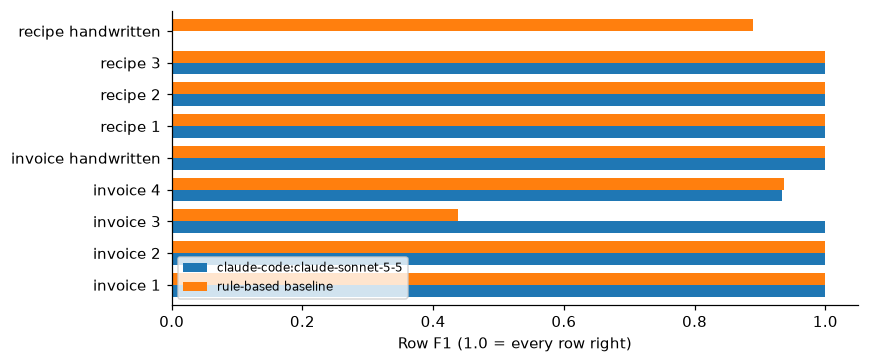

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
pivot = table.pivot(index="tier", columns="reader", values="F1")
pivot.plot.barh(ax=ax, width=0.75)
ax.set_xlabel("Row F1 (1.0 = every row right)"); ax.set_ylabel(""); ax.set_xlim(0, 1.05); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
head = []
for name, s in snaps.items():
    o = s["report"]["scorecard"]["overall"]; d = s["report"]["downstream"]
    head.append({"reader": name, "split": s["split"], "silent error rate": o["silent_error_rate"], "catch rate": o["catch_rate"],
                 "rows F1": o["rows"]["f1"], "class flips if all rows approved": d["approve_all"]["class_flips"],
                 "class flips if only unflagged approved": d["approve_unflagged"]["class_flips"],
                 "weekly profit error, approve all ($)": d["approve_all"]["weekly_profit_error"]})
pd.DataFrame(head).round(3)

,reader,split,silent error rate,catch rate,rows F1,class flips if all rows approved,class flips if only unflagged approved,"weekly profit error, approve all ($)"
0,rule-based baseline,all,0.0,None,0.863,2,5,-190.218
1,claude-code:claude-sonnet-5-5,test,0.0,None,0.990,1,0,163.553


## Takeaways

* The model **reads**; code **computes**. A unit conversion or a cost is never produced by the model, so the arithmetic is the same on every run and is tested with hand-computed cases.
* Every row is either right, or **flagged with a reason and a source quote**, or refused with no value. The number to watch is the **silent error rate** (a wrong, unflagged row): it is the only error a reviewer cannot see.
* A cost is not abstract: a new beef price moves an item's margin and can flip its menu class, and it also shifts its category's thresholds, so items whose own cost did not change can change class too. That is why the downstream effect of a parsing error is scored, with and without approving flagged rows.
* A person always approves. The overlay is opt-in and kept out of the portfolio's committed results.

**Limits.** The invoices are constructed or rendered by the project's own generator, so real invoices will be messier. There is no OCR, one call per document, no yield model, and beverage ingredients stocked in fluid ounces are refused. See the README for the full list.